# Day 11 | LSTM: Keep Useful Context

**KGP Talkie | Day 11**

We use small, made-up sentences. Positive = 1. Negative = 0. This example is for learning the steps, not judging real reviews. Run from top to bottom using **KGP Talkie (course)**.

## 1. Import our tools

TensorFlow runs the neural network. NumPy holds labels as numbers. Pandas shows results as a table. We use the packages already installed in the course environment.

In [1]:
# TensorFlow includes Keras, which gives us ready neural-network layers.
import tensorflow as tf

In [2]:
# NumPy stores the numeric labels used for training.
import numpy as np

In [3]:
# Pandas makes a readable prediction table.
import pandas as pd

In [4]:
# Seed 42 repeats the initial random choices for this small lesson.
tf.keras.utils.set_random_seed(42)

## 2. Give the model short examples with known labels

Each sentence is one input. Its label is the answer we want the model to learn. We keep test sentences separate, so their answers do not change the weights.

In [5]:
# These 12 sentences have positive labels. The line breaks only make the list easier to read.
positive = ["i like this movie", "i like this book", "i love this game",
            "i love this movie", "we love this book", "we like this movie",
            "this movie is great", "this book is good", "this game is fun",
            "we love this movie", "i like this game", "i do not hate this movie"]

In [6]:
# These 12 sentences have negative labels, including a sentence with "not".
negative = ["i hate this movie", "i hate this book", "i dislike this game",
            "i dislike this movie", "we dislike this book", "we hate this movie",
            "this movie is bad", "this book is boring", "this game is awful",
            "we hate this game", "i hate this game", "i do not like this movie"]

In [7]:
# Join the two lists; positive sentences come first, then negative sentences.
train_texts = positive + negative

In [8]:
# Repeat 1 for each positive example and 0 for each negative example, in the same order.
train_labels = np.array([1] * len(positive) + [0] * len(negative), dtype="float32")

In [9]:
# These eight sentences are not in the training list. We already know their labels.
test_texts = ["we like this book", "we love this game", "this book is great", "i do not hate this book",
              "we hate this book", "we dislike this game", "this game is bad", "i do not like this book"]

In [10]:
# The first four are positive, and the last four are negative.
test_labels = np.array([1, 1, 1, 1, 0, 0, 0, 0], dtype="float32")

## 3. Turn text into token IDs

A token is one text piece. We use whole words. `adapt()` builds the vocabulary from training sentences only. `output_sequence_length=8` leaves room for all our short sentences and adds zero padding after the real words.

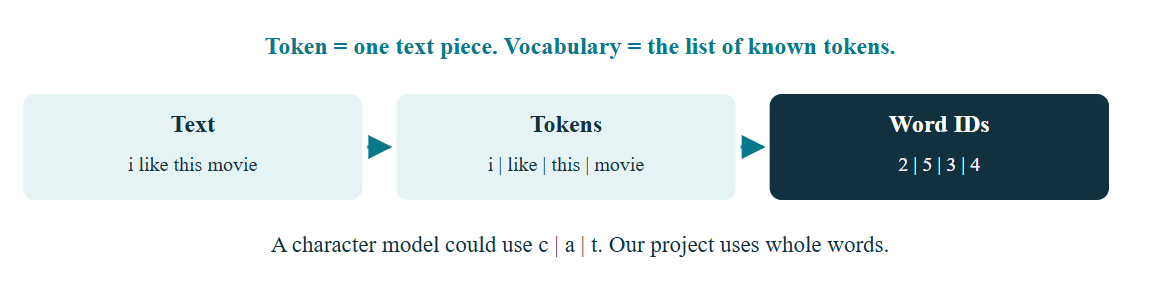

In [11]:
# int means word IDs; length 8 fits our sentences without removing words.
vectorizer = tf.keras.layers.TextVectorization(output_mode="int", output_sequence_length=8)

In [12]:
# Learn the vocabulary without reading test sentences.
vectorizer.adapt(tf.constant(train_texts))

In [13]:
# Each training sentence becomes a row of eight integer IDs.
train_ids = vectorizer(tf.constant(train_texts))

In [14]:
# Reuse the training vocabulary to encode test sentences.
test_ids = vectorizer(tf.constant(test_texts))

In [15]:
# Compare the first sentence and its IDs. Zero entries are added padding.
print(train_texts[0], "\nIDs:", train_ids[0].numpy())

i like this movie 
IDs: [ 3 10  2  4  0  0  0  0]


In [16]:
# Index 0 is padding. [UNK] is the special ID for unknown tokens.
vocabulary = vectorizer.get_vocabulary()
pd.DataFrame({"ID": range(len(vocabulary)), "token": vocabulary})

,ID,token
0,0,
1,1,[UNK]
2,2,this
3,3,i
4,4,movie
5,5,game
6,6,we
7,7,is
8,8,hate
9,9,book


## 4. Build the LSTM

The input is one list of token IDs. Embedding gives each real token a learned vector of eight numbers. `LSTM(16)` uses 16 values in each state vector. These small sizes keep our classroom model quick. `mask_zero=True` tells the recurrent layer to skip padding positions.

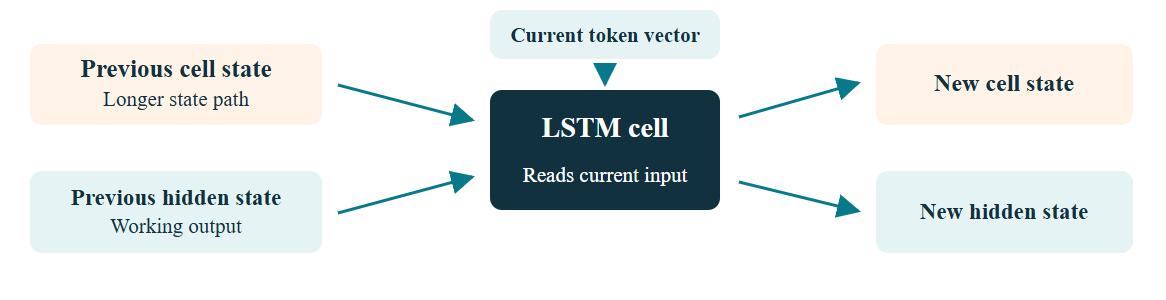

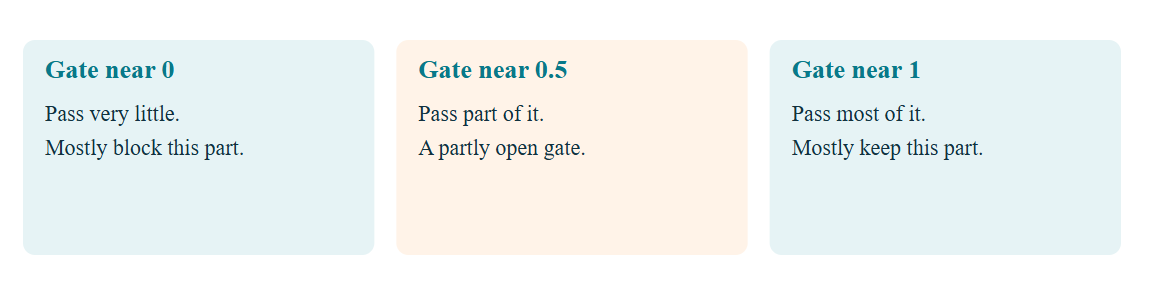

In [17]:
# Shape (8,) matches eight token positions; int64 matches the vectorizer output.
inputs = tf.keras.Input(shape=(8,), dtype="int64")

In [18]:
# One embedding row per vocabulary ID; learn eight numbers per token. Skip ID 0.
embedded = tf.keras.layers.Embedding(len(vocabulary), 8, mask_zero=True)(inputs)

In [19]:
# The default returns the last hidden state: one summary for the sentence.
state = tf.keras.layers.LSTM(16)(embedded)

In [20]:
# One sigmoid output estimates positive probability, so two output units are not needed.
output = tf.keras.layers.Dense(1, activation="sigmoid")(state)

In [21]:
# Connect the named input to the output as one complete model.
model = tf.keras.Model(inputs, output)

## 5. Train, then test

Binary cross-entropy is the loss for our two labels. Adam is the optimizer that changes weights to reduce that loss. Accuracy counts the fraction of correct class labels. The test set is used only after training.

In [22]:
# Adam uses its default learning rate; the loss matches one probability and labels 0/1.
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [23]:
# 100 small passes let the model learn this toy data. Batch 8 handles eight examples per update.
# verbose=0 hides the long per-epoch log; we show the final results below.
history = model.fit(train_ids, train_labels, epochs=100, batch_size=8, verbose=0)

In [24]:
# Compare starting and final training loss. This is not the test accuracy.
print("Training loss:", round(history.history["loss"][0], 3), "to", round(history.history["loss"][-1], 3))

Training loss: 0.694 to 0.183


In [25]:
# Test labels never entered fit; this score uses the eight separate test sentences.
test_loss, test_accuracy = model.evaluate(test_ids, test_labels, verbose=0)
print("Test accuracy:", round(test_accuracy, 3), "| Test loss:", round(test_loss, 3))

Test accuracy: 0.875 | Test loss: 0.39


In [26]:
# Get one positive probability per test sentence; reshape changes (8, 1) to (8,).
test_probabilities = model.predict(test_ids, verbose=0).reshape(-1)

In [27]:
# At least 0.5 selects positive (1); smaller values select negative (0).
test_predictions = (test_probabilities >= 0.5).astype(int)

In [28]:
# Read the true label beside the prediction; a high probability can still be wrong.
pd.DataFrame({"sentence": test_texts, "true label": test_labels.astype(int), "positive probability": test_probabilities.round(3), "predicted label": test_predictions})

,sentence,true label,positive probability,predicted label
0,we like this book,1,0.899,1
1,we love this game,1,0.910,1
2,this book is great,1,0.810,1
3,i do not hate this book,1,0.889,1
4,we hate this book,0,0.002,0
5,we dislike this game,0,0.001,0
6,this game is bad,0,0.103,0
7,i do not like this book,0,0.916,1


## 6. Try different inputs

These sentences were not in either list. We include a negation and then an unfamiliar phrase. Unknown word IDs show a vocabulary limit, not a new meaning the model has learned.

In [29]:
# New inputs include one phrase with words absent from the training vocabulary.
fresh_texts = ["we like this game", "this movie is awful", "i do not hate this game", "the film is amazing"]

In [30]:
# The same vocabulary and padding rules are used for every new input.
fresh_ids = vectorizer(tf.constant(fresh_texts))

In [31]:
# Use the trained weights; predict does not train again.
fresh_probabilities = model.predict(fresh_ids, verbose=0).reshape(-1)

In [32]:
# Show the class and the probability rather than just one label.
pd.DataFrame({"sentence": fresh_texts, "positive probability": fresh_probabilities.round(3), "predicted label": (fresh_probabilities >= 0.5).astype(int)})

,sentence,positive probability,predicted label
0,we like this game,0.898,1
1,this movie is awful,0.126,0
2,i do not hate this game,0.888,1
3,the film is amazing,0.765,1


In [33]:
# Inspect how the unfamiliar phrase was encoded. ID 1 is [UNK], not a real known word.
print(fresh_texts[-1], "\nIDs:", fresh_ids[-1].numpy())

the film is amazing 
IDs: [1 1 7 1 0 0 0 0]


## What this example shows

The text pipeline is **tokens > IDs > embeddings > LSTM state > class**. The data is very small. Check each prediction. A score here does not prove skill on real language, long reviews, or sarcasm.

Using LSTM on this tiny task does not prove that it is better than RNN. The handout explains the longer state path and gates.